In [148]:
import pandas as pd
import sqlite3

In [149]:
conn = sqlite3.connect("../data/checking-logs.sqlite")

In [150]:
pd.io.sql.read_sql("SELECT datetime FROM pageviews WHERE uid like 'user_%'", conn)

,datetime
0,2020-04-17 22:46:26.785035
1,2020-04-18 10:53:52.623447
2,2020-04-18 10:56:55.833899
3,2020-04-18 10:57:37.331258
4,2020-04-18 12:05:48.200144
...,...
982,2020-05-21 18:45:20.441142
983,2020-05-21 23:03:06.457819
984,2020-05-21 23:23:49.995349
985,2020-05-22 11:30:18.368990


In [151]:
df = pd.io.sql.read_sql(
"""--sql
        SELECT count(*) as views, date(datetime) as date
        FROM pageviews 
        WHERE uid like 'user_%'
        GROUP BY date   ORDER By date
        """, conn)
df.head()

,views,date
0,1,2020-04-17
1,23,2020-04-18
2,15,2020-04-19
3,3,2020-04-21
4,1,2020-04-22


In [152]:
# df.info()

In [153]:
df["date"] = df["date"].astype("datetime64[ns]")
# df['date'] = pd.to_datetime(df['date']) # [us]

In [154]:
# df.info()

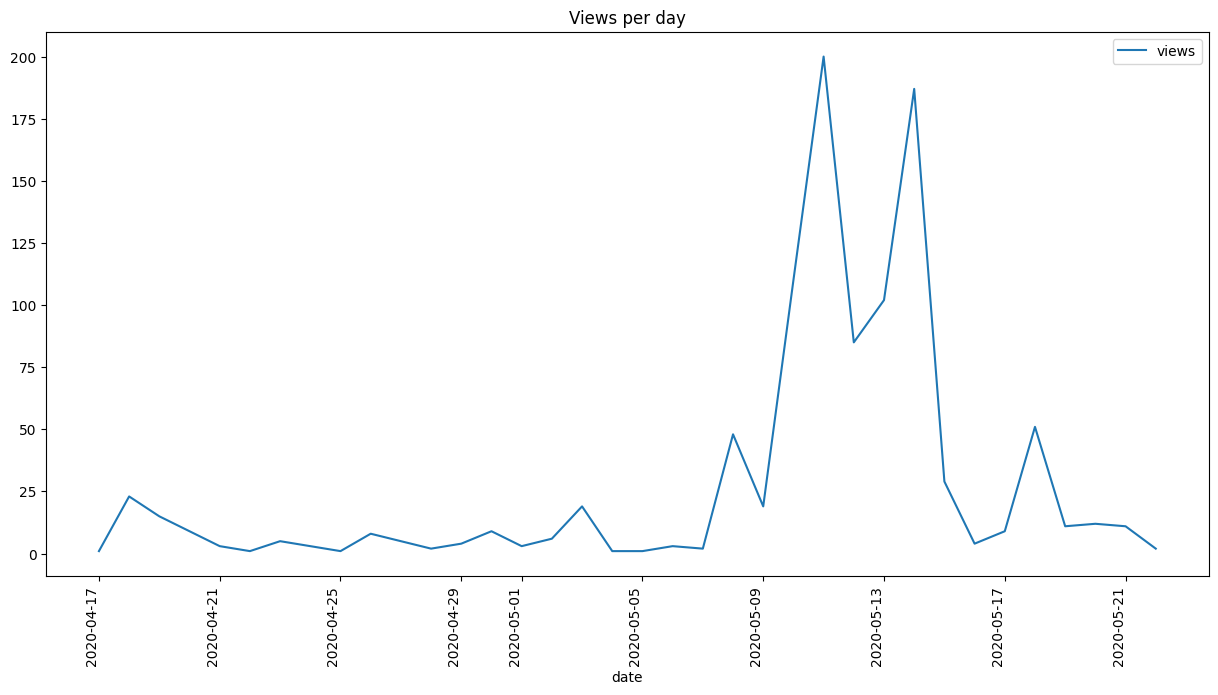

In [155]:
df.plot(
    x='date', 
    y='views', 
    title='Views per day', 
    rot=90, 
    figsize=(15, 8)
);

In [156]:
conn.close()